# Imports

In [2]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
import pandas as pd

import os, sys, subprocess, glob
sys.path.append("D:\\DATA\\ActivePIC")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from tqdm import tqdm
from rstools import RSoftCircuit
import rsoft_lib as rlib

# Hani's APD performance

Fiber mode injection + fiber mode phase metric

In [ ]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\"
save_dir = f"{working_dir}APD_v3_scan_wavelength\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "APD_v3"
filename = f"{filename_root}.ind"

# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")

    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.write(working_dir+filename)
    
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}{filename_root}_scan_Wav{wav_str}",
                   "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{filename_root}_scan_Wav{wav_str}.json'
    symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)

FemSIM mode injection + FemSIM mode phase metric

In [3]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\"
save_dir = f"{working_dir}APD_v3_FemSIMmode_scan_wavelength\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "APD_v3"
filename = f"{filename_root}.ind"

# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")
    mode_filename = f'{working_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00'

    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Mode_filename", mode_filename)
    c.write(working_dir+filename)
    
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}{filename_root}_FemSIMmode_scan_Wav{wav_str}",
                   "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{filename_root}_FemSIMmode_scan_Wav{wav_str}.json'
    symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)

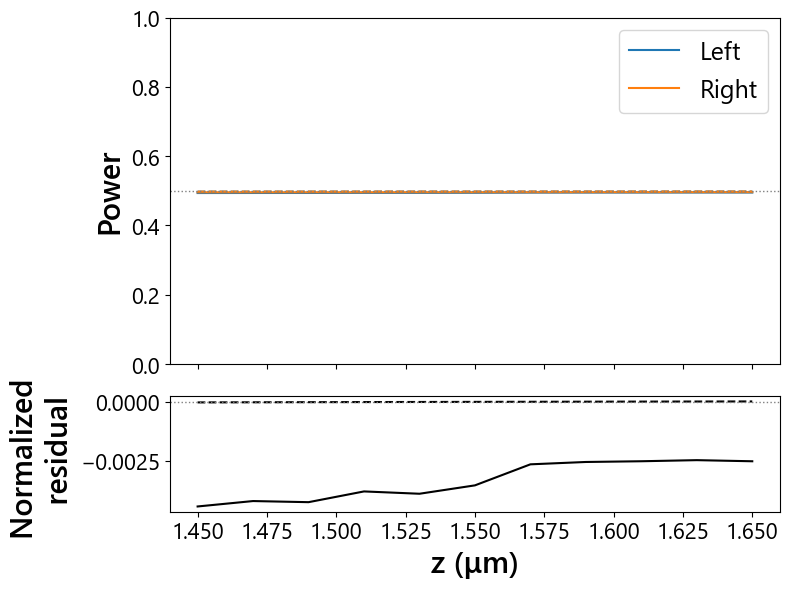

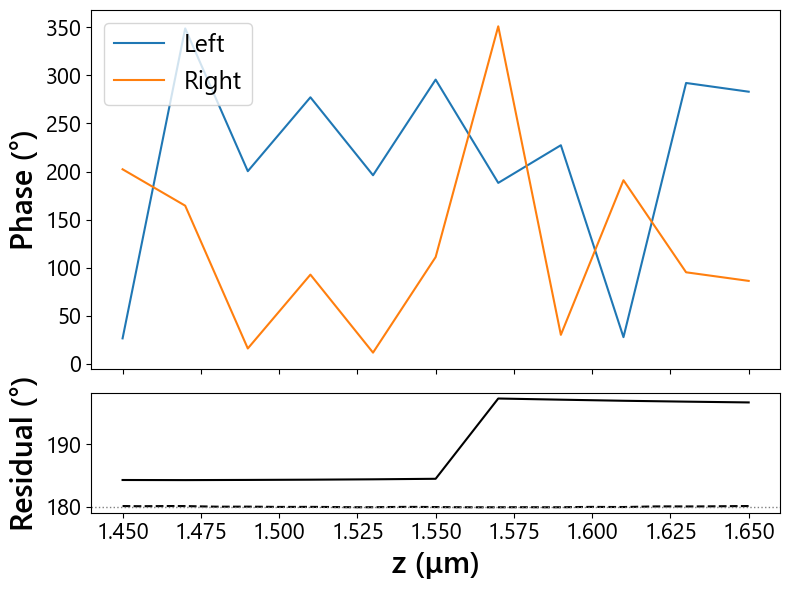

In [74]:
# Hani's reference metrics
reference_arr = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\HaniDesign\\v2\\v48_wavelength_by_wavelength.csv'
df_ref = pd.read_csv(reference_arr)

# BeamPROP metrics
save_dir = f"{working_dir}APD_v2_FemSIMmode_scan_wavelength\\"
wav_arr = np.load(f'{save_dir}APD_v2_Wav.npy')
monitor_files = glob.glob(f'{save_dir}*.mon')
monitor_arr = []
for wav in wav_arr:
    wav_str = f'{wav:0.3f}'.replace('.', 'p')
    monitor = rlib.read_monitor(f'{save_dir}APD_v2_FemSIMmode_scan_Wav{wav_str}.mon')
    monitor_arr.append(monitor.values[-1])
monitor_arr = np.array(monitor_arr)

# Plot
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitor_arr[:, 0], label='Left')
ax1.plot(wav_arr, monitor_arr[:, 2], label='Right')
ax1.plot(df_ref['lambda_um'], df_ref['top_power_surrogate']/2, linestyle='dashed', color='C0')
ax1.plot(df_ref['lambda_um'], df_ref['bottom_power_surrogate']/2, linestyle='dashed', color='C1')
ax1.axhline(0.5, color='grey', linestyle='dotted', linewidth=1)
ax1.set_ylabel('Power')
ax1.set_ylim(0, 1)
ax1.legend()
 
residual = (monitor_arr[:, 0] - monitor_arr[:, 2])/ monitor_arr[:, 2]
ax2.plot(wav_arr, residual, color='k')
ax2.plot(df_ref['lambda_um'], (df_ref['top_power_surrogate']-df_ref['bottom_power_surrogate'])/df_ref['bottom_power_surrogate'], 'k--')
ax2.axhline(0, color='grey', linestyle='dotted', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Normalized \n residual')
 
plt.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitor_arr[:, 1], label='Left')
ax1.plot(wav_arr, monitor_arr[:, 3], label='Right')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = (monitor_arr[:, 1] - monitor_arr[:, 3])%360
ax2.plot(wav_arr, residual, color='k')
ax2.plot(df_ref['lambda_um'], df_ref['phase_difference_deg']%360, 'k--')
ax2.axhline(180, color='grey', linestyle='dotted', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
plt.tight_layout()
plt.show()

In [67]:
# BeamPROP metrics
save_dir = f"{working_dir}APD_v2_scan_wavelength\\"
wav_arr = np.load(f'{save_dir}APD_v2_Wav.npy')
monitor_files = glob.glob(f'{save_dir}*.mon')
monitor_arr = []
for wav in wav_arr:
    wav_str = f'{wav:0.3f}'.replace('.', 'p')
    monitor = rlib.read_monitor(f'{save_dir}APD_v2_scan_Wav{wav_str}.mon')
    monitor_arr.append(monitor.values[-1])
monitor_arr = np.array(monitor_arr)

In [68]:
monitor_row = monitor_arr[np.isclose(wav_arr,1.55)][0]
monitor_row[1] - monitor_row[3] -180

4.429999999999978

In [66]:
df_ref

,lambda_um,phase_difference_rad,phase_difference_deg,phase_error_from_pi_deg,phase_error_from_pi_rad,top_power_surrogate,bottom_power_surrogate,normalized_power_imbalance_surrogate,top_loss_np_surrogate,bottom_loss_np_surrogate,differential_optical_path_um
0,1.450,-3.139922,-179.904265,0.095735,0.001671,0.995131,0.995166,-1.747310e-05,0.004881,0.004846,-0.724614
1,1.455,-3.140392,-179.931184,0.068816,0.001201,0.995153,0.995187,-1.684776e-05,0.004858,0.004825,-0.727222
2,1.460,-3.140191,-179.919675,0.080325,0.001402,0.995176,0.995208,-1.622960e-05,0.004836,0.004803,-0.729674
3,1.465,-3.139879,-179.901840,0.098160,0.001713,0.995198,0.995229,-1.561852e-05,0.004813,0.004782,-0.732101
4,1.470,-3.140010,-179.909343,0.090657,0.001582,0.995220,0.995250,-1.501442e-05,0.004791,0.004761,-0.734630
5,1.475,-3.140864,-179.958225,0.041775,0.000729,0.995242,0.995271,-1.441722e-05,0.004769,0.004741,-0.737329
6,1.480,-3.141658,-180.003746,-0.003746,-0.000065,0.995264,0.995291,-1.382681e-05,0.004748,0.004720,-0.740015
7,1.485,-3.141688,-180.005439,-0.005439,-0.000095,0.995285,0.995312,-1.324311e-05,0.004726,0.004700,-0.742522
8,1.490,-3.141561,-179.998191,0.001809,0.000032,0.995306,0.995332,-1.266602e-05,0.004705,0.004679,-0.744993
9,1.495,-3.141930,-180.019306,-0.019306,-0.000337,0.995328,0.995352,-1.209546e-05,0.004683,0.004659,-0.747580


C:\Users\runner\AppData\Local\Temp\ipykernel_15772\1292405047.py:22: RuntimeWarning: divide by zero encountered in log10
  null_depth_OPD = 10*np.log10(I_min/I_max)


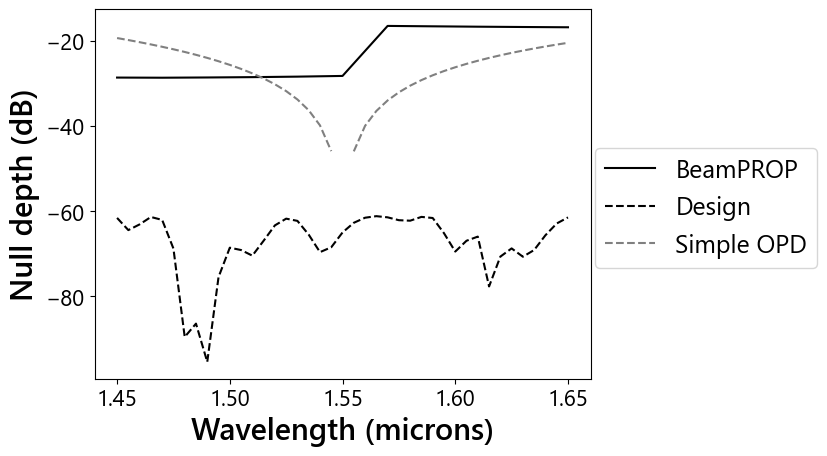

In [ ]:
# BeamPROP null depth
I1, I2, phi = monitor_arr[:, 0], monitor_arr[:, 2], (monitor_arr[:, 1] - monitor_arr[:, 3])%360
wav_BP = np.copy(wav_arr)

I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi * np.pi/180)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_BP = 10*np.log10(I_min/I_max)

# Design null depth
I1, I2, phi = df_ref['top_power_surrogate'], df_ref['bottom_power_surrogate'], df_ref['phase_difference_deg']%360
wav_design = np.copy(df_ref['lambda_um'])

I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi * np.pi/180)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_design = 10*np.log10(I_min/I_max)

# Simple OPD with power balanced
wav_OPD = np.copy(df_ref['lambda_um'])
I1, I2, OPD = 1, 1, (1.55/wav_OPD) * np.pi
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(OPD)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_OPD = 10*np.log10(I_min/I_max)


plt.figure()
plt.plot(wav_BP, null_depth_BP, 'k', label='BeamPROP')
plt.plot(wav_design, null_depth_design, 'k--', label='Design')
plt.plot(wav_OPD, null_depth_OPD, linestyle='dashed', color='grey', label='Simple OPD')
plt.xlabel('Wavelength (microns)')
plt.ylabel('Null depth (dB)')
plt.legend(loc=(1.01, 0.3))
plt.show()

In [ ]:
filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\APD_v2_FiberMode.mon'
monitors = rlib.read_monitor(filename_BP)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 0], label='Left')
ax1.plot(monitors.z, monitors.values[:, 2], label='Right')
ax1.set_ylabel('Power')
ax1.set_ylim(0, 1)
ax1.legend()
 
residual = monitors.values[:, 0] - monitors.values[:, 2]
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual')
 
plt.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 1], label='Left')
ax1.plot(monitors.z, monitors.values[:, 3], label='Right')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = (monitors.values[:, 3] - monitors.values[:,1])%360
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(180, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\APD_v2_FemSIMMode.mon'

# Hani APD + tricoupler performance

In [50]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\"
save_dir = f"{working_dir}APD_v2_Tricoupler_FemSIMmode_scan_wavelength\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "APD_v2_Tricoupler"
filename = f"{filename_root}.ind"

# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")
    mode_filename = f'{working_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00'

    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Mode_filename", mode_filename)
    c.write(working_dir+filename)
    
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}{filename_root}_FemSIMmode_scan_Wav{wav_str}",
                   "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{filename_root}_FemSIMmode_scan_Wav{wav_str}.json'
    symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)

C:\Users\runner\AppData\Local\Temp\ipykernel_15772\1650873074.py:50: RuntimeWarning: divide by zero encountered in log10
  null_depth_OPD = 10*np.log10(I_min/I_max)


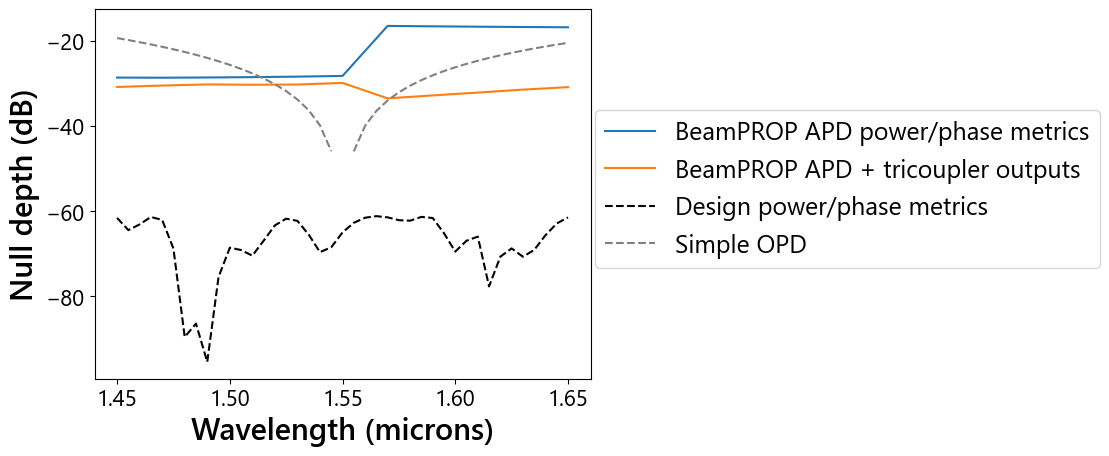

In [55]:
# BeamPROP metrics
save_dir = f"{working_dir}APD_v2_FemSIMmode_scan_wavelength\\"
wav_arr = np.load(f'{save_dir}APD_v2_Wav.npy')
monitor_files = glob.glob(f'{save_dir}*.mon')
monitor_arr = []
for wav in wav_arr:
    wav_str = f'{wav:0.3f}'.replace('.', 'p')
    monitor = rlib.read_monitor(f'{save_dir}APD_v2_FemSIMmode_scan_Wav{wav_str}.mon')
    monitor_arr.append(monitor.values[-1])
monitor_arr = np.array(monitor_arr)

I1, I2, phi = monitor_arr[:, 0], monitor_arr[:, 2], (monitor_arr[:, 1] - monitor_arr[:, 3])%360
wav_BP = np.copy(wav_arr)

I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi * np.pi/180)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_BP = 10*np.log10(I_min/I_max)

# BeamPROP + tricoupler null_depth
save_dir = f"{working_dir}APD_v2_Tricoupler_FemSIMmode_scan_wavelength\\"
wav_arr = np.load(f'{save_dir}APD_v2_Tricoupler_Wav.npy')
monitor_files = glob.glob(f'{save_dir}*.mon')
monitor_arr = []
for wav in wav_arr:
    wav_str = f'{wav:0.3f}'.replace('.', 'p')
    monitor = rlib.read_monitor(f'{save_dir}APD_v2_Tricoupler_FemSIMmode_scan_Wav{wav_str}.mon')
    monitor_arr.append(monitor.values[-1])
monitor_arr = np.array(monitor_arr)

null_depth_BP_tri = 10*np.log10(monitor_arr[:, 2]/(monitor_arr[:, 0] + monitor_arr[:, 4]))
wav_BP_tri = np.copy(wav_arr)

# Hani's reference metrics
reference_arr = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\HaniDesign\\v2\\v48_wavelength_by_wavelength.csv'
df_ref = pd.read_csv(reference_arr)

# Design null depth
I1, I2, phi = df_ref['top_power_surrogate'], df_ref['bottom_power_surrogate'], df_ref['phase_difference_deg']%360
wav_design = np.copy(df_ref['lambda_um'])

I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi * np.pi/180)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_design = 10*np.log10(I_min/I_max)

# Simple OPD with power balanced
wav_OPD = np.copy(df_ref['lambda_um'])
I1, I2, OPD = 1, 1, (1.55/wav_OPD) * np.pi
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(OPD)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
null_depth_OPD = 10*np.log10(I_min/I_max)


plt.figure()
plt.plot(wav_BP, null_depth_BP, 'C0', label='BeamPROP APD power/phase metrics')
plt.plot(wav_BP_tri, null_depth_BP_tri, 'C1', label='BeamPROP APD + tricoupler outputs')
plt.plot(wav_design, null_depth_design, 'k--', label='Design power/phase metrics')
plt.plot(wav_OPD, null_depth_OPD, linestyle='dashed', color='grey', label='Simple OPD')
plt.xlabel('Wavelength (microns)')
plt.ylabel('Null depth (dB)')
plt.legend(loc=(1.01, 0.3))
plt.show()


# Estimating null depth

In [2]:
df_phase = pd.read_csv('phase_summary_v18.txt', delim_whitespace=True)
df_power = pd.read_csv('power_imbalance_summary_v18.csv')
I1, I2 = df_power['raw_power_top'], df_power['raw_power_bottom']
phi = df_phase['raw_design_phase_rad']
OPD = (1.55/df_phase['wavelength_um']) * np.pi

# Design null depth
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi)
I_max = I1 + I2
null_depth_design = 10*np.log10(I_min/I_max)

# Phase imperfection only
I_min = 1 + np.cos(phi)
I_max = 1
null_depth_phase = 10*np.log10(I_min/I_max)

# Power imbalance only
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(np.pi*np.ones_like(phi))
I_max = I1 + I2
null_depth_power = 10*np.log10(I_min/I_max)

# Simple OPD with power balanced
I_min = 1 + np.cos(OPD)
I_max = 1
null_depth_OPD = 10*np.log10(I_min/I_max)

plt.figure()
plt.plot(df_phase['wavelength_um'], null_depth_design, label='Design')
plt.plot(df_phase['wavelength_um'], null_depth_phase, label='Phase imperfection only')
plt.plot(df_phase['wavelength_um'], null_depth_power, label='Power imbalance only')
plt.plot(df_phase['wavelength_um'], null_depth_OPD, label='Simple OPD')
plt.xlabel('Wavelength (microns)')
plt.ylabel('Null depth (dB)')
plt.legend()
plt.show()

C:\Users\runner\AppData\Local\Temp\ipykernel_5660\1101146477.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_phase = pd.read_csv('phase_summary_v18.txt', delim_whitespace=True)


FileNotFoundError: [Errno 2] No such file or directory: 'phase_summary_v18.txt'

In [46]:
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\"
filename = f'{working_dir}\\APD.mon'
filename_interference = f'{working_dir}\\APD_interference.mon'

sim = np.genfromtxt(filename, skip_header=5)
power_diff = sim[-1,4]/sim[-1,1]
phase_diff = sim[-1,3] - sim[-1,2]
I1, I2, phi = 1, power_diff, phase_diff * np.pi/180
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)
print(f'Null depth (before interference): {10*np.log10(I_min/I_max)} dB')

sim = np.genfromtxt(filename_interference, skip_header=5)
I_max = sim[-1,1] + sim[-1,5]
I_min = sim[-1, 3]
print(f'Null depth (before interference): {10*np.log10(I_min/I_max)} dB')

Null depth (before interference): -2.8297837150629297 dB
Null depth (before interference): -27.13588532383012 dB


In [57]:
wav, n0, L = 1550, 1.444, 1000
f = (wav/(2*n0*L)) + 1
err = 1.002
I1, I2, phi = 1, 1, 2*np.pi*((err*f-1)*1.444*1000)/(wav)
I_min = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(phi)
I_max = I1 + I2 + 2*np.sqrt(I1*I2)*np.cos(0)

print(f'Null depth : {10*np.log10(I_min/I_max)} dB')

Null depth : -40.92000768350064 dB


In [58]:
err*f*1.444

2.223438

# $n_{eff}$ comparison

In [6]:
grid_size

array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [8]:
neff_Hani['grid_size_um']

0    0.01
1    0.02
2    0.03
3    0.04
4    0.05
5    0.06
6    0.07
7    0.08
8    0.09
9    0.10
Name: grid_size_um, dtype: float64

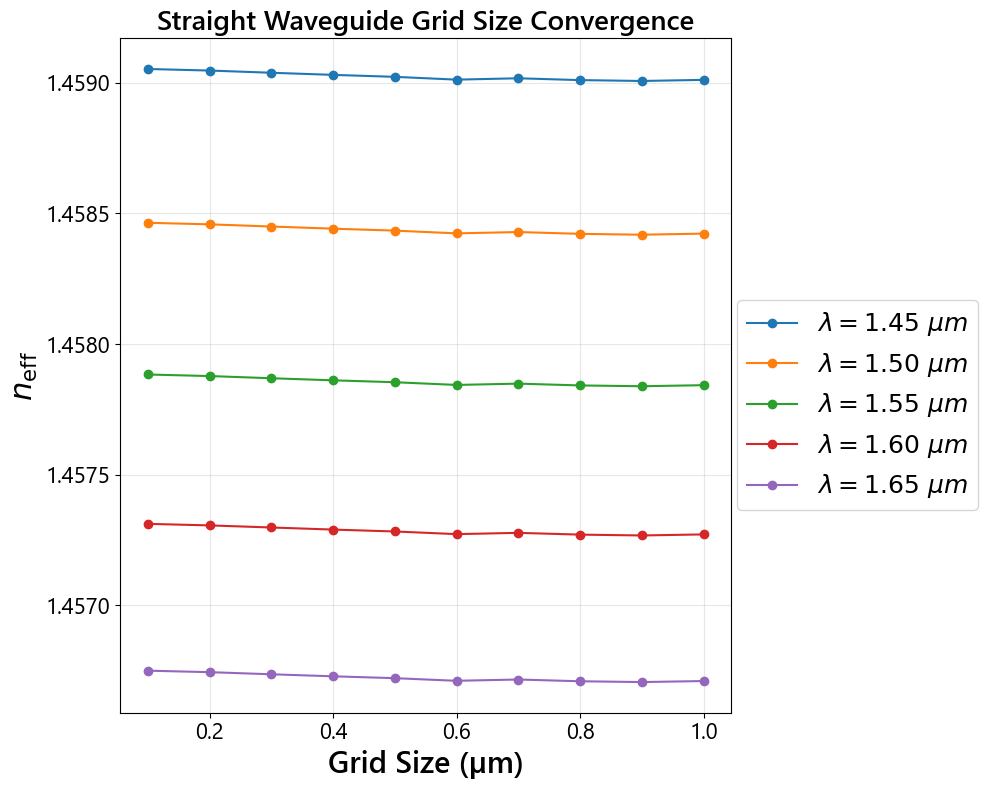

In [9]:
neff_Hani = pd.read_csv('Mode1_TE_neff_matrix.csv')

working_dir = "D:\\DATA\\SURF_2026\\ConvergenceTest\\"
save_dir =  os.path.join(working_dir,"StraightWaveguide_scan_gridSize_equal")

filename_root = "StraightWaveguide"

wav_arr = np.linspace (1.45, 1.65, 5)
colors = plt.cm.jet(np.linspace(0, 1, len(wav_arr)))

fig, ax = plt.subplots(figsize=(10, 8))

for i, (wav, color) in enumerate(zip(wav_arr, colors)):
    wav_str = f"{wav:.3f}".replace(".", "p")

    filename = os.path.join(save_dir, f"{filename_root}_scan_gridSize_equal_wav{wav_str}0p01to0p10.txt")

    sf = np.genfromtxt(filename, names=True, delimiter=",")

    grid_size = sf["Grid_Size"]
    neff = sf["Neff"]

    sort_ind = np.argsort(grid_size)
    grid_size = grid_size[sort_ind]
    neff = neff[sort_ind]

    reference_ind = np.where(np.isclose(grid_size, 0.10))
    
    neff_ref = neff[reference_ind[0]]
    delta_neff = neff - neff_ref

    ax.plot(grid_size, neff,  marker="o", color=f'C{i}', label=fr"$\lambda = {wav:.2f}\ \mu m$")
    # ax.plot(neff_Hani['grid_size_um'], neff_Hani[f'{round(wav*1000)}'], '--o', color=f'C{i}', mfc='none')

# Create the plot

plt.xlabel("Grid Size (µm)")
plt.ylabel( r"$n_{\rm eff}$")
plt.title("Straight Waveguide Grid Size Convergence")

plt.grid(True, alpha=0.3)
plt.legend(loc=(1.01, 0.3))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
working_dir = "D:\\DATA\\SURF_2026\\ConvergenceTest\\"
save_dir =  os.path.join(working_dir,"StraightWaveguide_scan_gridSize_equal")

filename_root = "StraightWaveguide"

wav_arr = np.linspace (1.45, 1.65, 5)
colors = plt.cm.jet(np.linspace(0, 1, len(wav_arr)))

fig, ax = plt.subplots(figsize=(10, 8))

for i, (wav, color) in enumerate(zip(wav_arr, colors)):
    wav_str = f"{wav:.3f}".replace(".", "p")

    filename = os.path.join(save_dir, f"{filename_root}_scan_gridSize_equal_wav{wav_str}0p01to0p10.txt")

    sf = np.genfromtxt(filename, names=True, delimiter=",")

    grid_size = sf["Grid_Size"]
    neff = sf["Neff"]

    sort_ind = np.argsort(grid_size)
    grid_size = grid_size[sort_ind]
    neff = neff[sort_ind]

    reference_ind = np.where(np.isclose(grid_size, 0.010))
    
    neff_ref = neff[reference_ind[0]]
    delta_neff = neff - neff_ref

    ax.plot(grid_size, neff/neff[0],  marker="o", color=f'C{i}', label=fr"$\lambda = {wav:.2f}\ \mu m$")
    ax.plot(neff_Hani['grid_size_um'], neff_Hani[f'{round(wav*1000)}']/neff_Hani[f'{round(wav*1000)}'][0], '--o', color=f'C{i}', mfc='none')

# Create the plot

plt.xlabel("Grid Size (µm)")
plt.ylabel( r"$n_{\rm eff} - n_{\rm eff}(0.01\ µm)$")
plt.title("Straight Waveguide Grid Size Convergence")

plt.grid(True, alpha=0.3)
plt.legend(loc=(1.01, 0.3))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'os' is not defined

# Two waveguide test

In [24]:
(power_path1[100]-power_path2[100])/power_path1[100]

-0.00013143389824583513

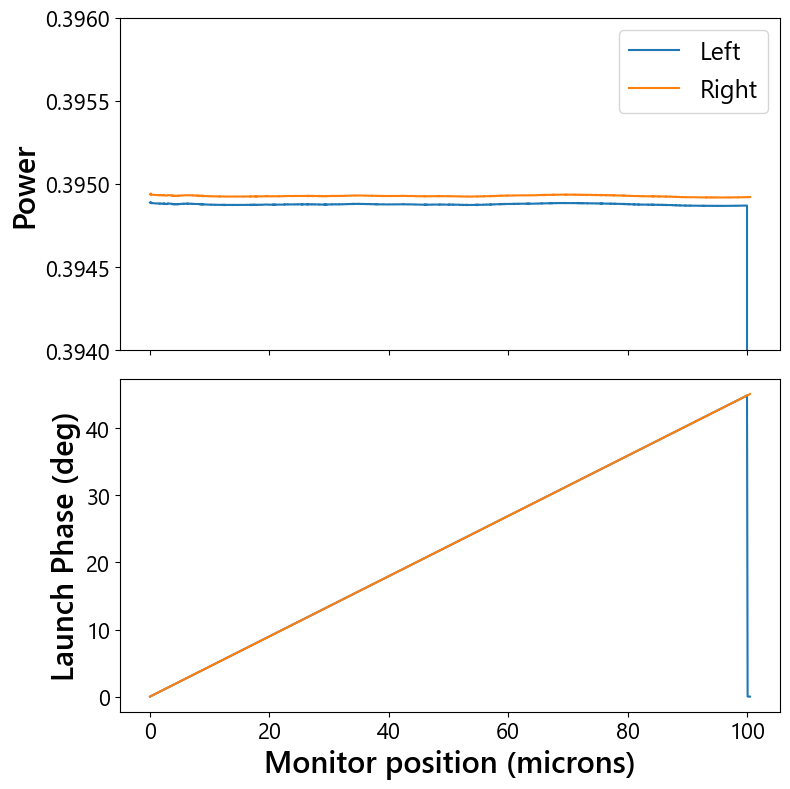

In [26]:
filename = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguide_BP_right.mon'

# Load the data, skipping the 4 header lines
data = np.loadtxt(filename, skiprows=5)

x = data[:, 0]
power_path1 = data[:, 1]
phase_path1 = data[:, 2]
power_path2 = data[:, 3]
phase_path2 = data[:, 4]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Power panel
ax1.plot(x, power_path1, label='Left', color='C0')
ax1.plot(x, power_path2, label='Right', color='C1')
ax1.set_ylim(0.394, 0.396)
ax1.set_ylabel('Power')
ax1.legend()

# Phase panel
ax2.plot(x, phase_path1, color='C0')
ax2.plot(x, phase_path2, color='C1')
ax2.set_ylabel('Launch Phase (deg)')
ax2.set_xlabel('Monitor position (microns)')

plt.tight_layout()
plt.show()


Z position: 100.0
Cropped amplitude/phase matrix shape: (43, 43)
X range: -1.700 to 1.700 um (43 points)
Y range: -1.700 to 1.700 um (43 points)


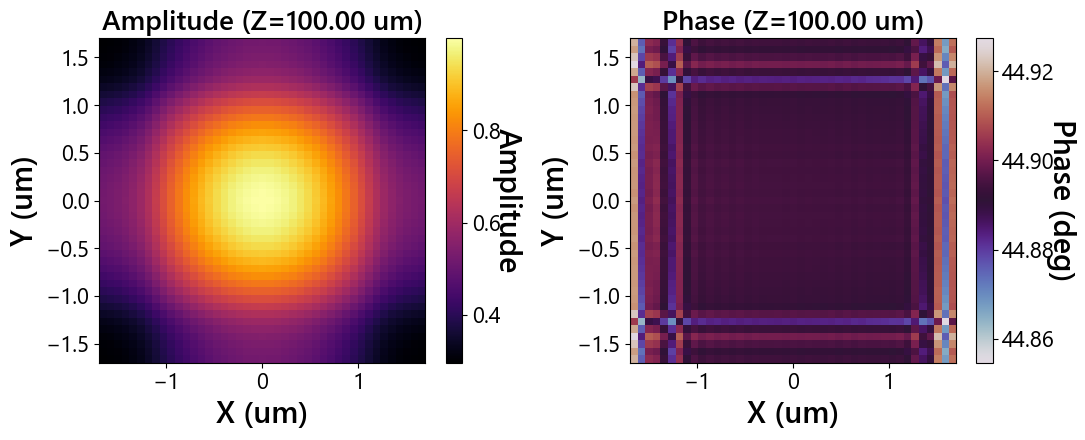

Z position: 100.5
Cropped amplitude/phase matrix shape: (42, 43)
X range: 294.590 to 297.978 um (42 points)
Y range: -1.700 to 1.700 um (43 points)


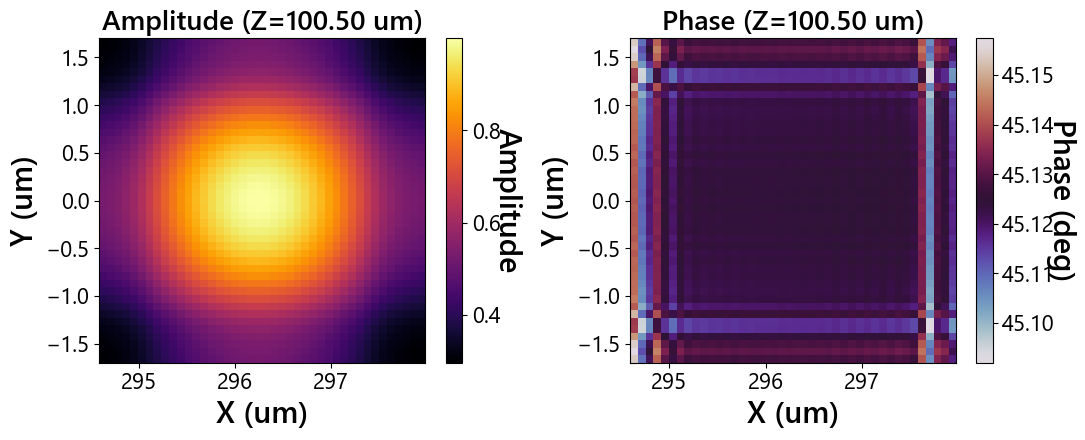

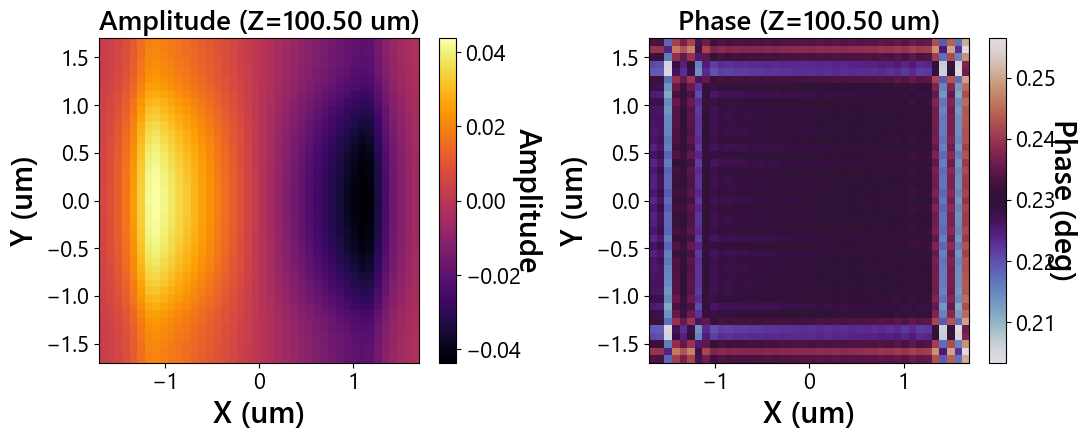

In [18]:
filename_left = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguide_BP_left.fld'
filename_right = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguide_BP_right.fld'

"""
Parse an RSoft BeamPROP 3D field file (OUTPUT_AMP_PHASE_3D format) and
extract amplitude/phase matrices within a specified cross-section window.

File format assumed:
    Line 1-3: RSoft marker lines (/rn/ls1, /r, /rq) -- ignored
    Line 4:   nx0  xmin  xmax  z_position  OUTPUT_AMP_PHASE_3D  Wavelength=...
    Line 5:   ny0  ymin  ymax
    Line 6:   0  y0  y1  y2  ... y(ny0-1)          (leading 0 is a placeholder token)
    Lines 7+: x_i  amp(x_i,y0) phase(x_i,y0)  amp(x_i,y1) phase(x_i,y1) ...
              (one row per X grid point, nx0 rows total)
"""

import numpy as np
import matplotlib.pyplot as plt


def parse_fld(path):
    """Parse an RSoft .fld (OUTPUT_AMP_PHASE_3D) file.

    Returns
    -------
    xgrid : (nx0,) array of X coordinates (um)
    ygrid : (ny0,) array of Y coordinates (um)
    amp   : (nx0, ny0) array of amplitude values
    phase : (nx0, ny0) array of phase values (degrees)
    zpos  : float, the Z position (um) at which this field was recorded
    """
    with open(path, 'r', newline=None) as f:
        lines = f.readlines()

    # Line index 3 (0-based) = 4th line = main header
    header = lines[3].split()
    nx0 = int(header[0])
    xmin, xmax = float(header[1]), float(header[2])
    zpos = float(header[3])

    # Line index 4 = Y-axis header
    yheader = lines[4].split()
    ny0 = int(yheader[0])
    ymin, ymax = float(yheader[1]), float(yheader[2])

    # Line index 5 = explicit Y grid values (first token is a placeholder, skip it)
    ygrid = np.array([float(v) for v in lines[5].split()[1:]])
    assert len(ygrid) == ny0, f"Expected {ny0} Y values, got {len(ygrid)}"

    xgrid = np.zeros(nx0)
    amp = np.zeros((nx0, ny0))
    phase = np.zeros((nx0, ny0))

    data_start = 6  # first data row is line index 6
    for i in range(nx0):
        toks = lines[data_start + i].split()
        xgrid[i] = float(toks[0])
        vals = np.array(toks[1:], dtype=float)
        amp[i, :] = vals[0::2]    # even indices = amplitude
        phase[i, :] = vals[1::2]  # odd indices  = phase

    return xgrid, ygrid, amp, phase, zpos


def crop_to_window(xgrid, ygrid, amp, phase, x_center=0.0, y_center=0.0, width=3.4, height=3.4):
    """Crop amplitude/phase matrices to a window of given width x height (um),
    centered at (x_center, y_center)."""
    x_half, y_half = width / 2, height / 2
    x_mask = (xgrid >= x_center - x_half) & (xgrid <= x_center + x_half)
    y_mask = (ygrid >= y_center - y_half) & (ygrid <= y_center + y_half)

    x_sub = xgrid[x_mask]
    y_sub = ygrid[y_mask]
    amp_sub = amp[np.ix_(x_mask, y_mask)]
    phase_sub = phase[np.ix_(x_mask, y_mask)]

    return x_sub, y_sub, amp_sub, phase_sub


def plot_amp_phase(x, y, amp, phase, zpos, save_path=None):
    """Plot amplitude and phase side by side.
 
    amp/phase have shape (nx, ny): X is axis 0 (rows), Y is axis 1 (columns).
    imshow always renders rows vertically and columns horizontally, so we
    transpose here to put X on the horizontal axis and Y on the vertical
    axis, matching the conventional plotting layout.
    """
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    extent = [x.min(), x.max(), y.min(), y.max()]  # [xmin,xmax,ymin,ymax] of displayed axes
 
    im0 = axes[0].imshow(amp.T, extent=extent, origin='lower', aspect='auto', cmap='inferno')
    axes[0].set_title(f'Amplitude (Z={zpos:.2f} um)')
    axes[0].set_xlabel('X (um)')
    axes[0].set_ylabel('Y (um)')
    cbar0 = plt.colorbar(im0, ax=axes[0])
    cbar0.set_label('Amplitude', rotation=270, labelpad=15)
 
    im1 = axes[1].imshow(phase.T, extent=extent, origin='lower', aspect='auto', cmap='twilight')
    axes[1].set_title(f'Phase (Z={zpos:.2f} um)')
    axes[1].set_xlabel('X (um)')
    axes[1].set_ylabel('Y (um)')
    cbar1 = plt.colorbar(im1, ax=axes[1])
    cbar1.set_label('Phase (deg)', rotation=270, labelpad=15)
 
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()

WINDOW_WIDTH = 3.4                       # um
WINDOW_HEIGHT = 3.4                      # um
CENTER_LEFT = (0.0, 0.0)                      # (x, y) in um
CENTER_RIGHT = (296.278, 0.0)                      # (x, y) in um

xgrid, ygrid, amp, phase, zpos = parse_fld(filename_left)
print('Z position:', zpos)

x_sub_left, y_sub_left, amp_sub_left, phase_sub_left = crop_to_window(
    xgrid, ygrid, amp, phase,
    x_center=CENTER_LEFT[0], y_center=CENTER_LEFT[1],
    width=WINDOW_WIDTH, height=WINDOW_HEIGHT
)

print("Cropped amplitude/phase matrix shape:", amp_sub_left.shape)
print(f"X range: {x_sub_left.min():.3f} to {x_sub_left.max():.3f} um ({len(x_sub_left)} points)")
print(f"Y range: {y_sub_left.min():.3f} to {y_sub_left.max():.3f} um ({len(y_sub_left)} points)")

plot_amp_phase(x_sub_left, y_sub_left, amp_sub_left, phase_sub_left, zpos, save_path=None)

# # Save matrices for downstream use
# np.savez("field_cropped.npz", x=x_sub, y=y_sub, amplitude=amp_sub, phase=phase_sub, z=zpos)

xgrid, ygrid, amp, phase, zpos = parse_fld(filename_right)
print('Z position:', zpos)

x_sub_right, y_sub_right, amp_sub_right, phase_sub_right = crop_to_window(
    xgrid, ygrid, amp, phase,
    x_center=CENTER_RIGHT[0], y_center=CENTER_RIGHT[1],
    width=WINDOW_WIDTH, height=WINDOW_HEIGHT
)

print("Cropped amplitude/phase matrix shape:", amp_sub_right.shape)
print(f"X range: {x_sub_right.min():.3f} to {x_sub_right.max():.3f} um ({len(x_sub_right)} points)")
print(f"Y range: {y_sub_right.min():.3f} to {y_sub_right.max():.3f} um ({len(y_sub_right)} points)")

plot_amp_phase(x_sub_right, y_sub_right, amp_sub_right, phase_sub_right, zpos, save_path=None)

plot_amp_phase(x_sub_left, y_sub_left, amp_sub_right-amp_sub_left[:-1,:], phase_sub_right-phase_sub_left[:-1,:], zpos, save_path=None)